## Agentic RAG z MCP

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mzarnecki/course_llm_agent_apps_with_langchain_and_langgraph/blob/main/notebooks/pl/8_6_Agentic_RAG_with_MCP.ipynb)

| | |
|---|---|
| 🎯 **Czego się nauczysz** | Udostępnianie źródeł wiedzy jako serwerów MCP (narzędzia + zasoby), agent sam wybierający źródła i wyszukujący iteracyjnie, a następnie kontrolowalny graf agentic RAG w LangGraph: plan → równoległe wyszukiwanie → ocena → ponowny plan → odpowiedź z cytowaniami. |
| 🔑 **Klucze API** | `OPENAI_API_KEY` |
| 💲 **Koszt API** | niski – około 30 krótkich zapytań |
| ⏱️ **Czas wykonania** | ~2–3 min (każde wywołanie narzędzia MCP uruchamia lokalny proces serwera) |

### Instalacja bibliotek

In [1]:
# Zainstaluj bezpośrednie zależności używane w tym notebooku.
# Pomijane, gdy brak pip, np. w środowisku `uv sync`, które ma je już zainstalowane (zob. README).
import importlib.util
if importlib.util.find_spec("pip"):
    %pip install -qU langgraph langchain langchain-openai langchain-mcp-adapters fastmcp rank-bm25 python-dotenv
# Google Colab: dodaj OPENAI_API_KEY w panelu Secrets (🔑) i zezwól notatnikowi na dostęp.
# Odkomentuj te linie, aby wczytać klucz z Colab Secrets do bieżącej sesji:
# from google.colab import userdata
# import os
# os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
# Lokalnie umieść OPENAI_API_KEY=... w pliku .env; nie commituj klucza.

Note: you may need to restart the kernel to use updated packages.


## Klasyczny RAG vs agentic RAG

**Klasyczny RAG** zawsze robi to samo: *jeden* retriever, *jedno* wyszukiwanie z pytaniem użytkownika, a potem generowanie.

```
pytanie ──► retriever ──► top-k fragmentów ──► LLM ──► odpowiedź
```

**Agentic RAG** oddaje sterowanie wyszukiwaniem modelowi. To LLM decyduje:

| Decyzja | Przykład |
|---|---|
| **Czy** w ogóle szukać | „Co oznacza skrót MCP?” → odpowiedź bez wyszukiwania |
| **Które źródło** wybrać | pytanie o regulamin → baza wiedzy, „ile wydała Anna?” → baza SQL |
| **Jak** odpytać źródło | przeredagować pytanie na słowa kluczowe albo napisać SQL |
| **Czy dowody wystarczą** | brakuje liczby → kolejne wyszukiwanie z doprecyzowanym zapytaniem (iteracyjne wyszukiwanie) |

```
                ┌──────────── za mało, doprecyzuj ─────────────┐
                ▼                                              │
pytanie ──► plan ──► baza wiedzy (MCP) ──────┐                 │
                └──► baza sprzedaży (MCP) ───┴──► ocena dowodów ──► odpowiedź + cytowania
```

### Dlaczego MCP?

**Model Context Protocol** to otwarty standard łączenia aplikacji LLM z danymi i narzędziami. Każde źródło staje się **serwerem** MCP, a agent łączy się z nim jako **klient**. Ten sam serwer działa z LangChain, Claude Desktop, IDE czy dowolnym innym klientem MCP i może być rozwijany oraz wdrażany przez zespół, który jest właścicielem danych.

| Element MCP | Kto steruje | Do czego go tu używamy |
|---|---|---|
| **Tools** (narzędzia) | model | `search_knowledge_base`, `get_document`, `run_sql`, `describe_schema` |
| **Resources** (zasoby) | aplikacja | `schema://sales` – schemat bazy wstrzykiwany do promptu SQL |
| **Prompts** (szablony) | użytkownik | (szablony – tu nieużywane) |

## 1. Dwa serwery MCP

### Serwer bazy wiedzy

Regulaminy sklepu przeszukiwane algorytmem BM25 (`rank-bm25`). `search_knowledge_base` zwraca krótkie fragmenty, a `get_document` pozwala agentowi przeczytać cały dokument, gdy fragment nie wystarcza. **Docstringi narzędzi mają znaczenie** – to je czyta model, wybierając źródło.

In [2]:
%%writefile kb_server.py
# ruff: noqa: E501
import re

from fastmcp import FastMCP
from rank_bm25 import BM25Okapi

mcp = FastMCP("knowledge-base")

DOCUMENTS = {
    "returns": "Zwroty. Produkty można zwrócić w ciągu 30 dni od dostawy, jeśli są nieużywane i w oryginalnym opakowaniu. "
    "Ze względów higienicznych otwarte słuchawki można zwrócić tylko wtedy, gdy są wadliwe. "
    "Pieniądze zwracamy w ciągu 14 dni na pierwotną metodę płatności.",
    "warranty": "Gwarancja. Cała elektronika ma 24-miesięczną gwarancję. Wadliwe produkty naprawiamy, wymieniamy lub zwracamy za nie pieniądze. "
    "Reklamację zgłoś w portalu wsparcia, podając numer zamówienia.",
    "loyalty": "Program lojalnościowy. Poziom zależy od łącznej wartości DOSTARCZONYCH zamówień z ostatnich 12 miesięcy "
    "(zamówienia anulowane i zwrócone się nie liczą): Silver od 2000 EUR, Gold od 5000 EUR, Platinum od 10000 EUR. "
    "Silver: darmowa dostawa standardowa. Gold: 5% rabatu na wszystkie zamówienia i darmowa dostawa ekspresowa. "
    "Platinum: 10% rabatu, darmowa dostawa ekspresowa i dedykowany doradca.",
    "shipping": "Dostawa. Dostawa standardowa trwa 3-5 dni roboczych i kosztuje 9 EUR, powyżej 200 EUR jest darmowa. "
    "Dostawa ekspresowa dociera następnego dnia roboczego i kosztuje 25 EUR. Wysyłamy do wszystkich krajów UE.",
    "payments": "Płatności. Akceptujemy karty, BLIK, PayPal i przelewy bankowe. Faktury wysyłamy e-mailem po nadaniu paczki.",
    "privacy": "Prywatność. Dane klientów przechowujemy w UE przez 5 lat od ostatniego zamówienia. "
    "Klient może poprosić o kopię lub usunięcie danych pod adresem privacy@shop.example.",
}


def tokenize(text: str) -> list[str]:
    return re.findall(r"\w+", text.lower())


ids = list(DOCUMENTS)
bm25 = BM25Okapi([tokenize(DOCUMENTS[i]) for i in ids])


@mcp.tool()
def search_knowledge_base(query: str, k: int = 2) -> list[dict]:
    """Przeszukaj regulaminy sklepu (zwroty, gwarancja, program lojalnościowy, dostawa, płatności, prywatność).
    Używaj krótkich zapytań ze słowami kluczowymi w języku polskim. Zwraca najlepiej pasujące dokumenty z ich id."""
    scores = bm25.get_scores(tokenize(query))
    best = sorted(zip(ids, scores, strict=True), key=lambda pair: pair[1], reverse=True)[:k]
    return [{"doc_id": doc_id, "text": DOCUMENTS[doc_id]} for doc_id, score in best if score > 0]


@mcp.tool()
def get_document(doc_id: str) -> str:
    """Zwróć pełny tekst jednego dokumentu regulaminu na podstawie jego id."""
    return DOCUMENTS.get(doc_id, f"Nieznane doc_id. Dostępne: {', '.join(ids)}")


if __name__ == "__main__":
    mcp.run(transport="stdio", show_banner=False, log_level="WARNING")

Overwriting kb_server.py


### Serwer bazy sprzedaży

Klienci i zamówienia w SQLite. Dostęp LLM do SQL to **granica zaufania**, więc serwer wymusza tryb tylko do odczytu na dwa sposoby: przyjmuje pojedynczy `SELECT`, a samo połączenie jest przełączone w `PRAGMA query_only`. Błędy wracają do modelu jako tekst, więc agent może sam poprawić swój SQL. Schemat jest dodatkowo publikowany jako **zasób** (resource) MCP.

In [3]:
%%writefile sales_db_server.py
# ruff: noqa: E501
import re
import sqlite3

from fastmcp import FastMCP

mcp = FastMCP("sales-db")

db = sqlite3.connect(":memory:", check_same_thread=False)
db.executescript("""
CREATE TABLE customers (id INTEGER PRIMARY KEY, name TEXT, city TEXT);
CREATE TABLE orders (
    id INTEGER PRIMARY KEY,
    customer_id INTEGER REFERENCES customers(id),
    order_date TEXT,      -- ISO date YYYY-MM-DD
    product TEXT,
    amount_eur REAL,
    status TEXT           -- delivered | cancelled | returned
);
INSERT INTO customers VALUES
    (1, 'Anna Nowak', 'Kraków'), (2, 'Jan Kowalski', 'Warszawa'),
    (3, 'Maria Wiśniewska', 'Gdańsk'), (4, 'Piotr Zieliński', 'Poznań');
INSERT INTO orders VALUES
    (1, 1, '2026-02-03', 'Laptop', 1800, 'delivered'),
    (2, 1, '2026-05-14', 'Klawiatura', 120, 'delivered'),
    (3, 1, '2026-08-30', 'Słuchawki bezprzewodowe', 299, 'delivered'),
    (4, 1, '2026-10-02', 'Mysz', 45, 'cancelled'),
    (5, 2, '2025-06-10', 'Telewizor 55', 2500, 'delivered'),
    (6, 2, '2026-01-15', 'Laptop', 2400, 'delivered'),
    (7, 2, '2026-04-02', 'Monitor 27', 900, 'delivered'),
    (8, 2, '2026-09-20', 'Smartphone', 1500, 'delivered'),
    (9, 2, '2026-11-20', 'Słuchawki bezprzewodowe', 350, 'returned'),
    (10, 3, '2026-03-03', 'Aparat', 3200, 'delivered'),
    (11, 3, '2026-07-07', 'Obiektyw', 2900, 'delivered'),
    (12, 4, '2026-11-01', 'Słuchawki bezprzewodowe', 349, 'delivered');
""")
db.execute("PRAGMA query_only = ON")  # defence in depth: the connection cannot write


def schema() -> str:
    return "\n".join(row[0] for row in db.execute("SELECT sql FROM sqlite_master WHERE type = 'table'"))


@mcp.resource("schema://sales")
def schema_resource() -> str:
    """SQL schema of the sales database."""
    return schema()


@mcp.tool()
def describe_schema() -> str:
    """Zwróć schemat SQL bazy sprzedaży (klienci i zamówienia)."""
    return schema()


@mcp.tool()
def run_sql(query: str) -> list[dict]:
    """Wykonaj JEDNO zapytanie SQL SELECT (tylko odczyt) na bazie sprzedaży (customers, orders) i zwróć do 50 wierszy. Używaj do faktów o konkretnych klientach, zamówieniach, kwotach i datach."""
    if not re.match(r"^\s*(select|with)\b", query, re.IGNORECASE) or ";" in query.strip().rstrip(";"):
        raise ValueError("Dozwolone jest tylko pojedyncze zapytanie SELECT.")
    cursor = db.execute(query)
    columns = [column[0] for column in cursor.description]
    return [dict(zip(columns, row, strict=True)) for row in cursor.fetchmany(50)]


if __name__ == "__main__":
    mcp.run(transport="stdio", show_banner=False, log_level="WARNING")

Overwriting sales_db_server.py


## 2. Połączenie przez `MultiServerMCPClient`

`langchain-mcp-adapters` zamienia narzędzia wielu serwerów MCP w zwykłe narzędzia LangChain. Przy transporcie `stdio` klient uruchamia każdy serwer jako podproces (w produkcji zwykle używa się `"transport": "streamable_http"` z adresem URL i nagłówkami uwierzytelniania).

In [4]:
import sys

from dotenv import load_dotenv
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain_openai import ChatOpenAI

load_dotenv()
llm = ChatOpenAI(model="gpt-6.1-terra", reasoning_effort="none")
TODAY = "2026-11-25"  # stała data, aby „ostatnie 12 miesięcy” dawały ten sam wynik przy każdym uruchomieniu

client = MultiServerMCPClient(
    {
        "knowledge_base": {"transport": "stdio", "command": sys.executable, "args": ["kb_server.py"]},
        "sales_db": {"transport": "stdio", "command": sys.executable, "args": ["sales_db_server.py"]},
    }
)
tools = await client.get_tools()
for t in tools:
    print(f"🔧 {t.name}: {t.description.splitlines()[0]}")

🔧 search_knowledge_base: Przeszukaj regulaminy sklepu (zwroty, gwarancja, program lojalnościowy, dostawa, płatności, prywatność).
🔧 get_document: Zwróć pełny tekst jednego dokumentu regulaminu na podstawie jego id.
🔧 describe_schema: Zwróć schemat SQL bazy sprzedaży (klienci i zamówienia).
🔧 run_sql: Wykonaj JEDNO zapytanie SQL SELECT (tylko odczyt) na bazie sprzedaży (customers, orders) i zwróć do 50 wierszy. Używaj do faktów o konkretnych klientach, zamówieniach, kwotach i datach.


Narzędzia można też wywołać bezpośrednio. MCP zwraca listę bloków treści; w ostatnim wywołaniu widać zabezpieczenie trybu tylko do odczytu:

In [5]:
tool = {t.name: t for t in tools}


def text_of(result) -> str:
    return "\n".join(block["text"] for block in result if block["type"] == "text")


print(text_of(await tool["search_knowledge_base"].ainvoke({"query": "zwrot otwarte słuchawki"})))
print(text_of(await tool["run_sql"].ainvoke({"query": "SELECT status, COUNT(*) AS n FROM orders GROUP BY status"})))
print(text_of(await tool["run_sql"].ainvoke({"query": "DELETE FROM orders"})))

[{"doc_id":"returns","text":"Zwroty. Produkty można zwrócić w ciągu 30 dni od dostawy, jeśli są nieużywane i w oryginalnym opakowaniu. Ze względów higienicznych otwarte słuchawki można zwrócić tylko wtedy, gdy są wadliwe. Pieniądze zwracamy w ciągu 14 dni na pierwotną metodę płatności."}]
[{"status":"cancelled","n":1},{"status":"delivered","n":10},{"status":"returned","n":1}]
Error calling tool 'run_sql': Dozwolone jest tylko pojedyncze zapytanie SELECT.


Oraz **zasób** ze schematem – odczytywany przez aplikację, a nie wybierany przez model:

In [6]:
resources = await client.get_resources("sales_db", uris=["schema://sales"])
SCHEMA = resources[0].as_string()
print(SCHEMA)

CREATE TABLE customers (id INTEGER PRIMARY KEY, name TEXT, city TEXT)
CREATE TABLE orders (
    id INTEGER PRIMARY KEY,
    customer_id INTEGER REFERENCES customers(id),
    order_date TEXT,      -- ISO date YYYY-MM-DD
    product TEXT,
    amount_eur REAL,
    status TEXT           -- delivered | cancelled | returned
)


## 3. Agentic RAG v1 – agent z narzędziami sam wybiera źródła

Najprostszy agentic RAG: przekazujemy `create_agent` wszystkie narzędzia MCP i prompt systemowy opisujący źródła. Pętla agenta (*rozumuj → wywołaj narzędzie → obserwuj → …*) daje nam za darmo wybór źródeł i iteracyjne wyszukiwanie.

In [7]:
import json

from langchain.agents import create_agent

SYSTEM_PROMPT = f"""Jesteś asystentem obsługi klienta sklepu internetowego z elektroniką. Dziś jest {TODAY}. Odpowiadaj po polsku.
Źródła:
- narzędzia bazy wiedzy: regulaminy sklepu (zwroty, gwarancja, program lojalnościowy, dostawa, płatności, prywatność)
- narzędzia bazy sprzedaży: fakty o konkretnych klientach i ich zamówieniach
Zasady:
- Używaj tylko tych źródeł, których wymaga pytanie; na pytania ogólne odpowiadaj bez narzędzi.
- Fakty o kliencie sprawdzaj w bazie danych (w razie wątpliwości najpierw sprawdź schemat).
- Jeśli dowody są niepełne, szukaj ponownie z doprecyzowanym zapytaniem lub w innym źródle.
- Odpowiadaj zwięźle i cytuj źródła, np. [kb:loyalty] lub [sql]."""

rag_agent = create_agent(llm, tools=tools, system_prompt=SYSTEM_PROMPT)


async def ask(question: str) -> None:
    result = await rag_agent.ainvoke({"messages": [{"role": "user", "content": question}]})
    print(f"❓ {question}")
    for message in result["messages"]:
        for call in getattr(message, "tool_calls", []):
            print(f"   🔧 {call['name']}({json.dumps(call['args'], ensure_ascii=False)})")
    print(f"💬 {result['messages'][-1].text}\n")

Cztery pytania, cztery różne strategie wyszukiwania – zobacz, które narzędzia wybiera agent:

In [8]:
for question in [
    "Co oznacza skrót MCP?",                                                          # bez wyszukiwania
    "Czy mogę zwrócić otwarte słuchawki bezprzewodowe? Działają bez zarzutu.",        # baza wiedzy
    "Ile zamówień złożyła Anna Nowak w 2026 roku i jaka była ich łączna wartość?",    # SQL
    "Jaki poziom programu lojalnościowego ma Jan Kowalski i jakie ma korzyści?",      # oba źródła, multi-hop
]:
    await ask(question)

❓ Co oznacza skrót MCP?
💬 MCP to **Model Context Protocol** – protokół umożliwiający modelom AI łączenie się z zewnętrznymi narzędziami i źródłami danych w ujednolicony sposób.

❓ Czy mogę zwrócić otwarte słuchawki bezprzewodowe? Działają bez zarzutu.
   🔧 search_knowledge_base({"query": "zwrot otwarte słuchawki bezprzewodowe higiena odstąpienie", "k": 3})
💬 Niestety nie. Ze względów higienicznych otwarte słuchawki można zwrócić tylko wtedy, gdy są wadliwe. Skoro działają bez zarzutu, zwrot nie jest możliwy. [kb:returns]

❓ Ile zamówień złożyła Anna Nowak w 2026 roku i jaka była ich łączna wartość?
   🔧 describe_schema({})
   🔧 run_sql({"query": "SELECT c.id, c.name, c.city, COUNT(o.id) AS order_count, COALESCE(SUM(o.amount_eur), 0) AS total_eur FROM customers c LEFT JOIN orders o ON o.customer_id = c.id AND o.order_date >= '2026-01-01' AND o.order_date < '2027-01-01' WHERE c.name = 'Anna Nowak' GROUP BY c.id, c.name, c.city"})
💬 Anna Nowak złożyła w 2026 roku **4 zamówienia** o łączne

Ostatnie pytanie jest **wieloetapowe (multi-hop)**: agent musi najpierw poznać regułę (*dostarczone zamówienia, ostatnie 12 miesięcy*) z bazy wiedzy, a potem policzyć właściwą sumę w SQL. Dane Jana zawierają trzy pułapki: telewizor kupiony ponad 12 miesięcy temu, zwrócone słuchawki i sumę tuż poniżej progu Gold. Poprawna odpowiedź to **Silver** (2400 + 900 + 1500 = 4800 EUR).

Agent jest elastyczny, ale przepływ sterowania zapisany jest w prompcie – trudno go testować i trudno cokolwiek zagwarantować. Gdy potrzebujesz gwarancji, zapisz pętlę jawnie.

## 4. Agentic RAG v2 – jawna pętla w LangGraph

Te same serwery MCP, ale teraz to **my** definiujemy kroki, a LLM podejmuje decyzje tylko wewnątrz nich:

| Węzeł | Decyzja LLM | Gwarancja ze strony grafu |
|---|---|---|
| `plan` | które źródła, jakie zapytania (structured output) | zawsze co najmniej jeden plan przed odpowiedzią |
| `search_kb`, `query_db` | treść zapytania SQL | źródła działają **równolegle** (`Send`), SQL zawsze dostaje zasób ze schematem |
| `grade` | czy dowody wystarczą? czego brakuje? | maksymalnie `MAX_ROUNDS` rund wyszukiwania |
| `answer` | końcowe sformułowanie | odpowiedź tylko na podstawie zebranych dowodów, z cytowaniami |

In [9]:
import operator
from typing import Annotated, TypedDict

from langgraph.graph import END, START, StateGraph
from langgraph.types import Send
from pydantic import BaseModel, Field

MAX_ROUNDS = 3


class Plan(BaseModel):
    kb_queries: list[str] = Field(default_factory=list, description="Zapytania ze słowami kluczowymi (po polsku) do bazy wiedzy z regulaminami; pusta lista, jeśli niepotrzebne")
    db_tasks: list[str] = Field(default_factory=list, description="Pytania o dane, na które odpowie SQL; pusta lista, jeśli niepotrzebne")


class Grade(BaseModel):
    sufficient: bool = Field(description="True, jeśli dowody w pełni odpowiadają na pytanie")
    missing: str = Field(description="Czego jeszcze brakuje; pusty tekst, jeśli dowody wystarczą")


class RagState(TypedDict, total=False):
    question: str
    plan: Plan
    evidence: Annotated[list[str], operator.add]  # równoległe wyszukiwania doklejają tu wyniki
    rounds: int
    feedback: str
    answer: str


async def plan(state: RagState) -> RagState:
    prompt = (
        f"Dziś jest {TODAY}. Zaplanuj wyszukiwanie dla poniższego pytania.\n"
        "Źródła: baza wiedzy = regulaminy sklepu; baza danych = klienci i zamówienia.\n"
        "Zwróć puste listy, jeśli pytanie nie wymaga danych sklepu.\n"
        f"Pytanie: {state['question']}\n"
        f"Dotychczasowe dowody:\n{chr(10).join(state.get('evidence', [])) or '-'}\n"
        f"Czego brakuje według oceniającego: {state.get('feedback') or '-'}"
    )
    return {"plan": await llm.with_structured_output(Plan).ainvoke(prompt), "rounds": state.get("rounds", 0) + 1}


def dispatch(state: RagState) -> list[Send] | str:
    sends = [Send("search_kb", {"query": q}) for q in state["plan"].kb_queries]
    sends += [Send("query_db", {"task": t}) for t in state["plan"].db_tasks]
    return sends or "answer"  # nic do wyszukania -> od razu odpowiedź


async def search_kb(task: dict) -> RagState:
    result = text_of(await tool["search_knowledge_base"].ainvoke({"query": task["query"]}))
    return {"evidence": [f"[kb] query={task['query']!r}\n{result}"]}


async def query_db(task: dict) -> RagState:
    sql = (await llm.ainvoke(
        f"Dziś jest {TODAY}. Napisz JEDNO zapytanie SQLite SELECT dla tego zadania. Zwróć tylko SQL, bez markdownu.\n"
        f"Schemat:\n{SCHEMA}\nZadanie: {task['task']}"
    )).text.strip()
    result = text_of(await tool["run_sql"].ainvoke({"query": sql}))  # błędy również wracają jako tekst
    return {"evidence": [f"[sql] task={task['task']!r}\n{sql}\n-> {result}"]}


async def grade(state: RagState) -> RagState:
    verdict = await llm.with_structured_output(Grade).ainvoke(
        f"Pytanie: {state['question']}\nDowody:\n{chr(10).join(state['evidence'])}\n"
        "Czy te dowody wystarczają, aby poprawnie i w pełni odpowiedzieć na pytanie? Sprawdź, czy wyniki SQL "
        "uwzględniają wszystkie reguły z regulaminów (daty, statusy, progi). Odpowiedz po polsku."
    )
    return {"feedback": "" if verdict.sufficient else verdict.missing}


def after_grade(state: RagState) -> str:
    return "answer" if not state["feedback"] or state["rounds"] >= MAX_ROUNDS else "plan"


async def answer(state: RagState) -> RagState:
    response = await llm.ainvoke(
        f"Odpowiedz po polsku na pytanie klienta, korzystając WYŁĄCZNIE z dowodów. Cytuj [kb:<doc_id>] lub [sql]. "
        f"Jeśli brak dowodów, odpowiedz z wiedzy ogólnej i zaznacz to.\n"
        f"Pytanie: {state['question']}\nDowody:\n{chr(10).join(state.get('evidence', [])) or '-'}"
    )
    return {"answer": response.text}


builder = StateGraph(RagState)
for node in (plan, search_kb, query_db, grade, answer):
    builder.add_node(node)
builder.add_edge(START, "plan")
builder.add_conditional_edges("plan", dispatch, ["search_kb", "query_db", "answer"])
builder.add_edge("search_kb", "grade")
builder.add_edge("query_db", "grade")
builder.add_conditional_edges("grade", after_grade, ["plan", "answer"])
builder.add_edge("answer", END)
agentic_rag = builder.compile()

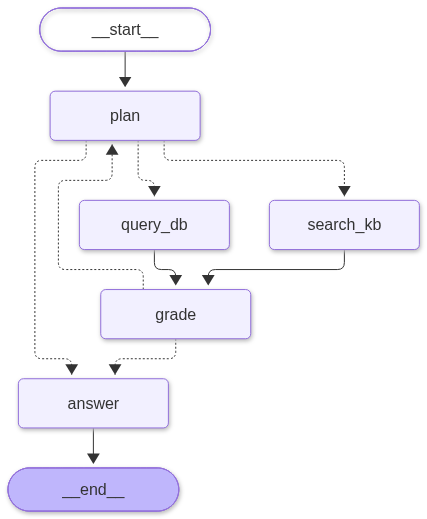

In [10]:
from IPython.display import Image

Image(agentic_rag.get_graph().draw_mermaid_png())

`astream(..., stream_mode="updates")` pokazuje każdy krok na bieżąco – plan, każde równoległe wyszukiwanie, werdykt oceniającego i ewentualne dodatkowe rundy:

In [11]:
async def run(question: str) -> None:
    print(f"❓ {question}")
    async for update in agentic_rag.astream({"question": question}, stream_mode="updates"):
        for node, change in update.items():
            if node == "plan":
                p = change["plan"]
                print(f"🧭 plan (runda {change['rounds']}): kb={p.kb_queries} db={p.db_tasks}")
            elif node in ("search_kb", "query_db"):
                print(f"🔎 {node}: {change['evidence'][0][:300]}")
            elif node == "grade":
                print(f"⚖️  ocena: {'wystarczające' if not change['feedback'] else 'brakuje → ' + change['feedback']}")
            elif node == "answer":
                print(f"💬 {change['answer']}\n")


await run("Jaki poziom programu lojalnościowego ma Jan Kowalski i jakie ma korzyści?")

❓ Jaki poziom programu lojalnościowego ma Jan Kowalski i jakie ma korzyści?
🧭 plan (runda 1): kb=['program lojalnościowy poziomy korzyści regulamin'] db=['Ustal poziom programu lojalnościowego klienta Jan Kowalski.']
🔎 search_kb: [kb] query='program lojalnościowy poziomy korzyści regulamin'
[{"doc_id":"loyalty","text":"Program lojalnościowy. Poziom zależy od łącznej wartości DOSTARCZONYCH zamówień z ostatnich 12 miesięcy (zamówienia anulowane i zwrócone się nie liczą): Silver od 2000 EUR, Gold od 5000 EUR, Platinum od 10000 
🔎 query_db: [sql] task='Ustal poziom programu lojalnościowego klienta Jan Kowalski.'
SELECT
    c.id,
    c.name,
    COUNT(o.id) AS delivered_orders,
    COALESCE(SUM(o.amount_eur), 0) AS delivered_amount_eur,
    NULL AS loyalty_tier
FROM customers AS c
LEFT JOIN orders AS o
    ON o.customer_id = c.id
   AND
⚖️  ocena: brakuje → Zapytanie SQL uwzględnia status dostarczenia, ale nie ogranicza zamówień do ostatnich 12 miesięcy. Brakuje sumy wartości dostarczonych 

In [12]:
await run("Piotr Zieliński chce zwrócić słuchawki bezprzewodowe kupione w tym miesiącu. Otworzył je i działają. Czy to możliwe?")
await run("Co oznacza skrót MCP?")

❓ Piotr Zieliński chce zwrócić słuchawki bezprzewodowe kupione w tym miesiącu. Otworzył je i działają. Czy to możliwe?
🧭 plan (runda 1): kb=['Zwrot słuchawek bezprzewodowych po otwarciu opakowania odstąpienie od umowy termin stan produktu wyjątki higieniczne'] db=['Sprawdź zamówienia Piotra Zielińskiego zawierające słuchawki bezprzewodowe kupione od 1 do 25 listopada 2026 r., w tym datę zakupu, sposób zakupu, status zamówienia i datę dostarczenia.']
🔎 search_kb: [kb] query='Zwrot słuchawek bezprzewodowych po otwarciu opakowania odstąpienie od umowy termin stan produktu wyjątki higieniczne'
[{"doc_id":"payments","text":"Płatności. Akceptujemy karty, BLIK, PayPal i przelewy bankowe. Faktury wysyłamy e-mailem po nadaniu paczki."}]
🔎 query_db: [sql] task='Sprawdź zamówienia Piotra Zielińskiego zawierające słuchawki bezprzewodowe kupione od 1 do 25 listopada 2026 r., w tym datę zakupu, sposób zakupu, status zamówienia i datę dostarczenia.'
SELECT
    o.order_date AS data_zakupu,
    NULL AS